In [ ]:
# 2. Construct a Feedforward Neural Network for Sign Language alphabet 
# recognition. Train the model using the training dataset and evaluate it 
# using the testing dataset. Display the training accuracy, testing accuracy 
# # and loss graph. 

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [2]:
# Step 1: Load training and testing datasets

train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

In [3]:
# Display the shape of training and testing datasets

print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)

Training Dataset Shape: (27455, 785)
Testing Dataset Shape: (7172, 785)


In [4]:
# Step 2: Separate labels and pixel values

X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

In [5]:
# Step 3: Convert labels into 24 consecutive classes

classes = np.sort(np.unique(y_train))

# Create a mapping for original labels
label_map = {label: index for index, label in enumerate(classes)}

y_train = np.array([label_map[label] for label in y_train])
y_test = np.array([label_map[label] for label in y_test])

In [6]:
# Step 4: Normalize pixel values between 0 and 1

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [7]:
# Step 5: Flatten images (28 x 28 = 784)

X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Training Input Shape:", X_train.shape)
print("Testing Input Shape:", X_test.shape)

Training Input Shape: (27455, 784)
Testing Input Shape: (7172, 784)


In [8]:
# Step 6: Split training data into training and validation sets

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [9]:
# Step 7: Build Feedforward Neural Network

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),

    # First hidden layer
    tf.keras.layers.Dense(256, activation="relu"),

    # Second hidden layer
    tf.keras.layers.Dense(128, activation="relu"),

    # Third hidden layer
    tf.keras.layers.Dense(64, activation="relu"),

    # Output layer for 24 alphabet classes
    tf.keras.layers.Dense(24, activation="softmax")
])

In [10]:
# Step 8: Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
# Step 9: Display model summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 243,672 (951.84 KB)

 Trainable params: 243,672 (951.84 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Step 10: Train the model

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.2422 - loss: 2.5313 - val_accuracy: 0.4189 - val_loss: 1.8353
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.5172 - loss: 1.5064 - val_accuracy: 0.5922 - val_loss: 1.2526
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6656 - loss: 1.0571 - val_accuracy: 0.7139 - val_loss: 0.9159
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.7553 - loss: 0.7747 - val_accuracy: 0.7643 - val_loss: 0.7131
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8112 - loss: 0.5834 - val_accuracy: 0.8201 - val_loss: 0.5377
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8590 - loss: 0.4408 - val_accuracy: 0.8660 - val_loss: 0.4047
Epoch 7/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8986 - loss: 0.3300 - val_accuracy: 0.8926 - val_loss: 0.3280
Epoch 8/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9272 - loss: 0.2505 - val_accu

In [13]:
# Step 11: Display training accuracy

train_accuracy = history.history["accuracy"][-1]

print("Training Accuracy: {:.2f}%".format(train_accuracy * 100))

Training Accuracy: 99.63%


In [14]:
# Step 12: Evaluate the model using testing dataset

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Testing Accuracy: {:.2f}%".format(test_accuracy * 100))
print("Testing Loss:", test_loss)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7522 - loss: 1.1227
Testing Accuracy: 75.22%
Testing Loss: 1.122689962387085


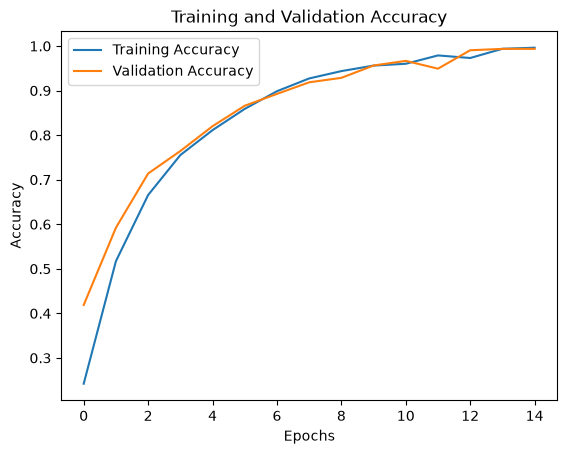

In [15]:
# Step 13: Plot training and validation accuracy

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

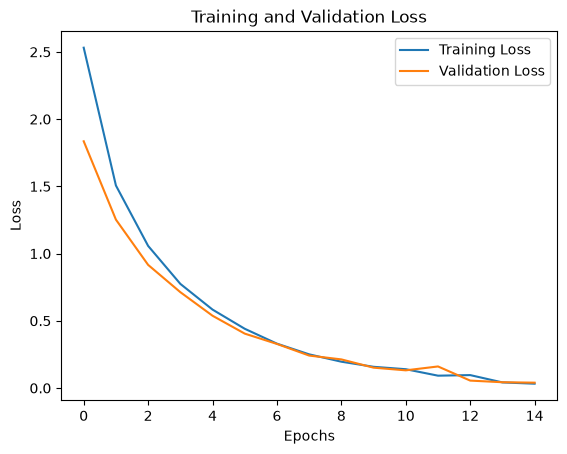

In [16]:
# Step 14: Plot training and validation loss

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()